# Predicting 30-Day Hospital Readmission in Patients with Diabetes

**Exploratory machine-learning and subgroup-performance analysis**

This notebook uses the UCI Diabetes 130-US Hospitals dataset (1999–2008) to explore prediction of an encounter followed by a recorded readmission within 30 days. It evaluates discrimination, probability calibration, and differences in subgroup performance.

> **Research-use only:** this historical dataset and exploratory model are not clinically validated and must not be used for patient-care decisions. The target means a `<30` readmission label in this dataset; `NO` does not prove the patient was never readmitted elsewhere or later.

## Prediction-time caveat
The feature set includes variables such as length of stay, laboratory/procedure counts, medication information, and diagnoses whose availability time is not established by this dataset. This is therefore an **encounter-level exploratory model**, not a validated admission-time prediction system. `discharge_disposition_id` is excluded as a potentially outcome-adjacent feature. Patient identifiers are excluded from predictors and used only to prevent patient overlap across splits.

## Workflow
1. Load and inspect the data. 2. Define the outcome. 3. Split by patient. 4. Fit a logistic-regression baseline. 5. Evaluate discrimination and calibration. 6. Compare subgroup metrics with uncertainty. 7. Export tables for reporting.

In [1]:
# If running in Google Colab, uncomment and run these lines to upload the dataset ZIP:
# from google.colab import files
# uploaded = files.upload()

from pathlib import Path
import zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             log_loss, confusion_matrix, precision_score, recall_score)
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as CalibrationLogisticRegression

RANDOM_STATE = 20261011
DATASET_ZIP = Path('diabetes+130-us+hospitals+for+years+1999-2008.zip')
if not DATASET_ZIP.exists():
    candidates = list(Path('/mnt/data').glob('diabetes+130-us+hospitals+for+years+1999-2008.zip'))
    if candidates:
        DATASET_ZIP = candidates[0]
if not DATASET_ZIP.exists():
    raise FileNotFoundError('Dataset ZIP not found. Download the UCI dataset and place its ZIP beside this notebook, or upload it in Colab.')

with zipfile.ZipFile(DATASET_ZIP) as zf:
    with zf.open('diabetic_data.csv') as f:
        df = pd.read_csv(f)
print(f'Rows: {len(df):,}; columns: {df.shape[1]:,}; unique patients: {df.patient_nbr.nunique():,}')
display(df.head())

Rows: 101,766; columns: 50; unique patients: 71,518


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. Data quality and target definition

The positive class is `readmitted == '<30'`. The negative class combines `'>30'` and `'NO'`. The interpretation is limited to the labels recorded in this dataset. Unknown categorical values represented as `?` are converted to missing values during preprocessing. The highly incomplete `weight` feature is excluded.

In [2]:
df = df.copy()
df['target_30d'] = (df['readmitted'].astype(str).str.strip() == '<30').astype(int)
missing = (df.astype(str).eq('?').sum() / len(df) * 100).sort_values(ascending=False)
missing_summary = pd.DataFrame({'percent_question_mark': missing[missing > 0].round(2)})
print('Recorded outcome distribution:')
print(df['readmitted'].value_counts(dropna=False).to_string())
print(f"Positive class rate (<30): {df['target_30d'].mean():.2%}")
print('\nLargest question-mark missingness percentages:')
display(missing_summary.head(12))

Recorded outcome distribution:
readmitted
NO     54864
>30    35545
<30    11357
Positive class rate (<30): 11.16%

Largest question-mark missingness percentages:


,percent_question_mark
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


## 2. Patient-level train, validation, and test split

A patient can have multiple encounters. We split by `patient_nbr` groups so that encounters from one patient do not appear across partitions. Validation data are used to fit probability calibration; the test set is held out for final evaluation.

In [3]:
# Use groups to ensure patient IDs do not cross partitions.
groups = df['patient_nbr'].to_numpy()
indices = np.arange(len(df))
first_split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
train_idx, temp_idx = next(first_split.split(indices, df['target_30d'], groups))
temp_groups = groups[temp_idx]
second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE + 1)
val_rel, test_rel = next(second_split.split(temp_idx, df.iloc[temp_idx]['target_30d'], temp_groups))
val_idx, test_idx = temp_idx[val_rel], temp_idx[test_rel]
train_df, val_df, test_df = df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()

train_patients, val_patients, test_patients = (set(x['patient_nbr']) for x in (train_df, val_df, test_df))
assert train_patients.isdisjoint(val_patients) and train_patients.isdisjoint(test_patients) and val_patients.isdisjoint(test_patients)
split_summary = pd.DataFrame({
    'partition':['train','validation','test'],
    'encounters':[len(train_df),len(val_df),len(test_df)],
    'unique_patients':[train_df.patient_nbr.nunique(),val_df.patient_nbr.nunique(),test_df.patient_nbr.nunique()],
    'positive_rate':[train_df.target_30d.mean(),val_df.target_30d.mean(),test_df.target_30d.mean()]
})
display(split_summary)
print('Patient-level split verified: no patient overlap.')

,partition,encounters,unique_patients,positive_rate
0,train,71195,50062,0.112396
1,validation,15264,10728,0.112487
2,test,15307,10728,0.107010


Patient-level split verified: no patient overlap.


## 3. Train a baseline logistic-regression model

Identifiers, target, raw readmission label, highly incomplete weight, and discharge disposition are excluded from predictors. This is a broad encounter-level feature set; because feature availability timing is not provided, do not interpret it as admission-time prediction. Numeric and categorical features are imputed and encoded in a preprocessing pipeline.

In [4]:
excluded = {'encounter_id','patient_nbr','readmitted','target_30d','weight','discharge_disposition_id'}
feature_cols = [c for c in df.columns if c not in excluded]
# Convert '?' to missing for categorical and numeric values.
X_all = df[feature_cols].replace('?', np.nan).copy()
y_all = df['target_30d'].to_numpy()
X_train, y_train = X_all.iloc[train_idx], y_all[train_idx]
X_val, y_val = X_all.iloc[val_idx], y_all[val_idx]
X_test, y_test = X_all.iloc[test_idx], y_all[test_idx]

num_cols = X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20))])
preprocess = ColumnTransformer([('numeric', numeric_pipe, num_cols), ('categorical', categorical_pipe, cat_cols)])
model = Pipeline([('preprocess', preprocess), ('classifier', LogisticRegression(max_iter=1000, class_weight=None, solver='liblinear', random_state=RANDOM_STATE))])
model.fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:,1]
p_test = model.predict_proba(X_test)[:,1]
print(f'Features: {len(feature_cols)} ({len(num_cols)} numeric, {len(cat_cols)} categorical)')
print('Model fitted.')

Features: 45 (10 numeric, 35 categorical)
Model fitted.


## 4. Calibration on validation data; evaluation on held-out test data

Sigmoid (Platt-style) and isotonic calibrators are fitted using validation predictions and labels, then evaluated on the untouched test set. ROC-AUC and average precision assess ranking/discrimination; Brier score and log loss assess probabilistic predictions. Expected calibration error (ECE) is a bin-dependent descriptive measure.

,model,roc_auc,average_precision,brier_score,log_loss,ece_10_bins,calibration_intercept,calibration_slope,mean_predicted_risk
0,Uncalibrated logistic,0.6368,0.1851,0.0933,0.3292,0.0096,-0.5279,0.7611,0.1126
1,Sigmoid calibrated,0.6368,0.1851,0.0929,0.3280,0.0051,0.0454,1.0482,0.1118
2,Isotonic calibrated,0.6342,0.1740,0.0930,0.3327,0.0048,-0.2281,0.9111,0.1118


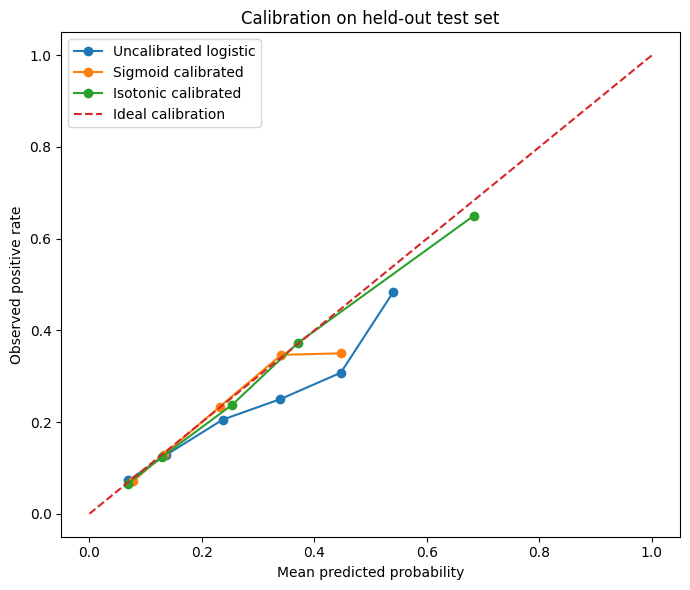

In [5]:
def safe_logit(p, eps=1e-6):
    p = np.clip(np.asarray(p), eps, 1-eps)
    return np.log(p/(1-p))

def ece_score(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    edges = np.linspace(0, 1, n_bins+1)
    total = len(y); ece = 0.0
    for i in range(n_bins):
        mask = (p >= edges[i]) & ((p < edges[i+1]) if i < n_bins-1 else (p <= edges[i+1]))
        if mask.any():
            ece += mask.sum()/total * abs(y[mask].mean() - p[mask].mean())
    return ece

# Sigmoid calibration on validation set.
sigmoid_cal = CalibrationLogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sigmoid_cal.fit(safe_logit(p_val).reshape(-1,1), y_val)
p_test_sigmoid = sigmoid_cal.predict_proba(safe_logit(p_test).reshape(-1,1))[:,1]
# Isotonic calibration on validation set.
isotonic_cal = IsotonicRegression(out_of_bounds='clip')
isotonic_cal.fit(p_val, y_val)
p_test_isotonic = isotonic_cal.predict(p_test)

def calibration_intercept_slope(y, p):
    lr = CalibrationLogisticRegression(C=1e6, max_iter=1000, random_state=RANDOM_STATE)
    lr.fit(safe_logit(p).reshape(-1,1), y)
    return float(lr.intercept_[0]), float(lr.coef_[0,0])

def metric_row(name, y, p):
    intercept, slope = calibration_intercept_slope(y,p)
    return {'model':name,'roc_auc':roc_auc_score(y,p),'average_precision':average_precision_score(y,p),
            'brier_score':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'ece_10_bins':ece_score(y,p,10),'calibration_intercept':intercept,
            'calibration_slope':slope,'mean_predicted_risk':float(np.mean(p))}

probabilities = {'Uncalibrated logistic':p_test, 'Sigmoid calibrated':p_test_sigmoid, 'Isotonic calibrated':p_test_isotonic}
calibration_results = pd.DataFrame([metric_row(k, y_test, v) for k,v in probabilities.items()])
display(calibration_results.round(4))

Path('outputs').mkdir(exist_ok=True)
plt.figure(figsize=(7,6))
for label, probs in probabilities.items():
    bins = np.linspace(0,1,11)
    means, observed = [], []
    for i in range(len(bins)-1):
        mask = (probs >= bins[i]) & ((probs < bins[i+1]) if i < len(bins)-2 else (probs <= bins[i+1]))
        if mask.sum() >= 20:
            means.append(probs[mask].mean()); observed.append(y_test[mask].mean())
    plt.plot(means, observed, marker='o', label=label)
plt.plot([0,1],[0,1], linestyle='--', label='Ideal calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed positive rate')
plt.title('Calibration on held-out test set'); plt.legend(); plt.tight_layout()
plt.savefig('outputs/calibration_plot.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Subgroup performance and fairness-related checks

This section reports recall and false-positive rate at a fixed illustrative threshold of 0.12, along with group size, positive-case count, precision, and mean predicted risk. The threshold is **not clinically selected or validated**. Differences may reflect sample size, prevalence, measurement, data collection, or model behaviour; no single metric proves that a model is fair or unfair.

In [6]:
THRESHOLD = 0.12
yhat = (p_test >= THRESHOLD).astype(int)
test_meta = test_df[['race','gender','age']].copy().reset_index(drop=True)
test_meta['y_true'] = y_test
test_meta['y_pred'] = yhat
test_meta['predicted_risk'] = p_test

def subgroup_table(data, group_col, min_group_n=1):
    rows=[]
    for group, g in data.groupby(group_col, dropna=False):
        y=g['y_true'].to_numpy(); pred=g['y_pred'].to_numpy()
        positives=int(y.sum()); negatives=int((y==0).sum())
        tp=int(((y==1)&(pred==1)).sum()); fn=int(((y==1)&(pred==0)).sum())
        fp=int(((y==0)&(pred==1)).sum()); tn=int(((y==0)&(pred==0)).sum())
        rows.append({'group_variable':group_col,'group':str(group),'n_encounters':len(g),'positive_cases':positives,
                     'positive_rate':float(y.mean()),'recall':tp/(tp+fn) if tp+fn else np.nan,
                     'false_positive_rate':fp/(fp+tn) if fp+tn else np.nan,
                     'precision':tp/(tp+fp) if tp+fp else np.nan,
                     'mean_predicted_risk':float(g['predicted_risk'].mean())})
    return pd.DataFrame(rows).sort_values('n_encounters',ascending=False)

subgroup_results = pd.concat([subgroup_table(test_meta, col) for col in ['race','gender','age']], ignore_index=True)
display(subgroup_results.round(4))
print(f'Illustrative threshold: {THRESHOLD:.2f}. Interpret subgroup differences cautiously, especially where positive-case counts are small.')

,group_variable,group,n_encounters,positive_cases,positive_rate,recall,false_positive_rate,precision,mean_predicted_risk
0,race,Caucasian,11479,1255,0.1093,0.4924,0.3090,0.1636,0.1134
1,race,AfricanAmerican,2905,305,0.1050,0.5213,0.3169,0.1617,0.1154
2,race,?,350,26,0.0743,0.3462,0.2253,0.1098,0.0921
3,race,Hispanic,279,25,0.0896,0.3600,0.1969,0.1525,0.0918
4,race,Other,199,17,0.0854,0.3529,0.2418,0.1200,0.0963
5,race,Asian,95,10,0.1053,0.6000,0.2118,0.2500,0.1036
6,gender,Female,8283,899,0.1085,0.4750,0.3062,0.1589,0.1121
7,gender,Male,7024,739,0.1052,0.5142,0.3034,0.1662,0.1132
8,age,[70-80),4039,452,0.1119,0.5398,0.3633,0.1577,0.1214
9,age,[60-70),3371,341,0.1012,0.5249,0.3086,0.1607,0.1112


Illustrative threshold: 0.12. Interpret subgroup differences cautiously, especially where positive-case counts are small.


## 6. Patient-level bootstrap uncertainty for overall metrics

The following optional cell resamples test patients (retaining all encounters for each sampled patient) to estimate percentile 95% intervals for selected metrics. Duplicate sampled patients are represented by repeated copies of their encounters. Bootstrap intervals reflect sampling uncertainty under this dataset/split, not uncertainty from external validation or changes in clinical practice.

In [7]:
# Set to 100 for a quicker run; increase to 300+ for a more stable exploratory interval.
N_BOOTSTRAPS = 100
rng = np.random.default_rng(RANDOM_STATE)
patient_values = test_df['patient_nbr'].to_numpy()
unique_patients = pd.unique(patient_values)
patient_rows = {pid: np.flatnonzero(patient_values == pid) for pid in unique_patients}
boot_rows = []
for b in range(N_BOOTSTRAPS):
    sampled_patients = rng.choice(unique_patients, size=len(unique_patients), replace=True)
    sampled_indices = np.concatenate([patient_rows[pid] for pid in sampled_patients])
    yb = y_test[sampled_indices]
    if len(np.unique(yb)) < 2:
        continue
    for label, probs in probabilities.items():
        pb = probs[sampled_indices]
        boot_rows.append({'bootstrap':b,'model':label,'roc_auc':roc_auc_score(yb,pb),
                          'average_precision':average_precision_score(yb,pb),
                          'brier_score':brier_score_loss(yb,pb),
                          'log_loss':log_loss(yb,pb,labels=[0,1])})
boot_df = pd.DataFrame(boot_rows)
ci_rows=[]
for label, g in boot_df.groupby('model'):
    for metric in ['roc_auc','average_precision','brier_score','log_loss']:
        ci_rows.append({'model':label,'metric':metric,'lower_95':g[metric].quantile(.025),'upper_95':g[metric].quantile(.975)})
bootstrap_intervals = pd.DataFrame(ci_rows)
display(bootstrap_intervals.round(4))

,model,metric,lower_95,upper_95
0,Isotonic calibrated,roc_auc,0.6203,0.6471
1,Isotonic calibrated,average_precision,0.1585,0.1926
2,Isotonic calibrated,brier_score,0.0892,0.0967
3,Isotonic calibrated,log_loss,0.3206,0.3453
4,Sigmoid calibrated,roc_auc,0.6231,0.6495
5,Sigmoid calibrated,average_precision,0.1680,0.2051
6,Sigmoid calibrated,brier_score,0.0891,0.0966
7,Sigmoid calibrated,log_loss,0.3178,0.3376
8,Uncalibrated logistic,roc_auc,0.6231,0.6495
9,Uncalibrated logistic,average_precision,0.1680,0.2051


## 7. Export results and research limitations

CSV outputs can be included in the repository after review. Do not commit patient-level data. The dataset is historical and the analysis is exploratory. The results do not establish clinical utility, causal relationships, or fairness. External validation, clear prediction-time definition, subgroup uncertainty, and clinical collaboration would be needed before any real-world use.

In [8]:
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)
split_summary.to_csv(output_dir/'split_summary.csv', index=False)
missing_summary.to_csv(output_dir/'missingness_summary.csv')
calibration_results.to_csv(output_dir/'calibration_metrics.csv', index=False)
subgroup_results.to_csv(output_dir/'subgroup_performance.csv', index=False)
bootstrap_intervals.to_csv(output_dir/'bootstrap_confidence_intervals.csv', index=False)
print('Saved outputs to:', output_dir.resolve())
print('\nResearch limitations to state in any report:')
print('- Historical U.S. hospital data from 1999–2008; practice patterns may differ today.')
print('- Target is a recorded <30-day readmission label; no recorded readmission is not proof of no later readmission.')
print('- Feature availability times are not established; not a validated admission-time model.')
print('- Subgroup comparisons are descriptive and sensitive to sample sizes and threshold choice.')
print('- No external or prospective clinical validation; not for patient-care decisions.')

Saved outputs to: /mnt/data/diabetes-readmission-ml/outputs

Research limitations to state in any report:
- Historical U.S. hospital data from 1999–2008; practice patterns may differ today.
- Target is a recorded <30-day readmission label; no recorded readmission is not proof of no later readmission.
- Feature availability times are not established; not a validated admission-time model.
- Subgroup comparisons are descriptive and sensitive to sample sizes and threshold choice.
- No external or prospective clinical validation; not for patient-care decisions.
